In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns

# Project directories
PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data" / "raw" / "Audio_Speech_Actors_01-24"

In [2]:
actor_folders = sorted(DATA_DIR.glob("Actor_*"))

print("Total actor folders:", len(actor_folders))

for folder in actor_folders:
    print(folder.name)

Total actor folders: 24
Actor_01
Actor_02
Actor_03
Actor_04
Actor_05
Actor_06
Actor_07
Actor_08
Actor_09
Actor_10
Actor_11
Actor_12
Actor_13
Actor_14
Actor_15
Actor_16
Actor_17
Actor_18
Actor_19
Actor_20
Actor_21
Actor_22
Actor_23
Actor_24


In [3]:
audio_files = list(DATA_DIR.rglob("*.wav"))

print("Total WAV recordings:", len(audio_files))

print("\nFirst 10 recordings:")

for file in audio_files[:10]:
    print(file.name)

Total WAV recordings: 1440

First 10 recordings:
03-01-01-01-01-01-01.wav
03-01-01-01-01-02-01.wav
03-01-01-01-02-01-01.wav
03-01-01-01-02-02-01.wav
03-01-02-01-01-01-01.wav
03-01-02-01-01-02-01.wav
03-01-02-01-02-01-01.wav
03-01-02-01-02-02-01.wav
03-01-02-02-01-01-01.wav
03-01-02-02-01-02-01.wav


In [4]:
sample_file = audio_files[0]

audio, sr = sf.read(sample_file)

print("File:", sample_file.name)
print("Sample rate:", sr)
print("Audio shape:", audio.shape)
print("Duration:", len(audio) / sr, "seconds")
print("Data type:", audio.dtype)

File: 03-01-01-01-01-01-01.wav
Sample rate: 48000
Audio shape: (158558,)
Duration: 3.3032916666666665 seconds
Data type: float64


In [5]:
# RAVDESS filename Decoding 

# Extract filename without extension
filename = sample_file.stem

# Split filename using hyphen
identifiers = filename.split("-")

# Assign identifiers
modality, vocal_channel, emotion, intensity, statement, repetition, actor = identifiers

print("Modality:", modality)
print("Vocal channel:", vocal_channel)
print("Emotion:", emotion)
print("Intensity:", intensity)
print("Statement:", statement)
print("Repetition:", repetition)
print("Actor:", actor)

Modality: 03
Vocal channel: 01
Emotion: 01
Intensity: 01
Statement: 01
Repetition: 01
Actor: 01


# Create the metadata extraction function

In [7]:

# RAVDESS identifier mappings

modality_mapping = {
    "01": "Full-AV",
    "02": "Video-only",
    "03": "Audio-only"
}

vocal_channel_mapping = {
    "01": "Speech",
    "02": "Song"
}

emotion_mapping = {
    "01": "Neutral",
    "02": "Calm",
    "03": "Happy",
    "04": "Sad",
    "05": "Angry",
    "06": "Fearful",
    "07": "Disgust",
    "08": "Surprised"
}

intensity_mapping = {
    "01": "Normal",
    "02": "Strong"
}

statement_mapping = {
    "01": "Kids",
    "02": "Dogs"
}


def extract_metadata(file_path):

    identifiers = file_path.stem.split("-")

    if len(identifiers) != 7:
        raise ValueError(f"Invalid filename: {file_path.name}")

    modality, vocal_channel, emotion, intensity, statement, repetition, actor = identifiers

    return {
        "recording_id": file_path.stem,
        "file_path": str(file_path),
        "actor_id": int(actor),
        "emotion_id": int(emotion),
        "emotion_label": emotion_mapping.get(emotion),
        "intensity": intensity_mapping.get(intensity),
        "statement_id": int(statement),
        "repetition": int(repetition),
        "modality": modality_mapping.get(modality),
        "vocal_channel": vocal_channel_mapping.get(vocal_channel)
    }

In [8]:
# generate dataframe 

metadata = []

for file_path in audio_files:

    try:
        record = extract_metadata(file_path)
        metadata.append(record)

    except ValueError as error:
        print(error)

df = pd.DataFrame(metadata)

df.head()

,recording_id,file_path,actor_id,emotion_id,emotion_label,intensity,statement_id,repetition,modality,vocal_channel
0,03-01-01-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,1,Neutral,Normal,1,1,Audio-only,Speech
1,03-01-01-01-01-02-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,1,Neutral,Normal,1,2,Audio-only,Speech
2,03-01-01-01-02-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,1,Neutral,Normal,2,1,Audio-only,Speech
3,03-01-01-01-02-02-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,1,Neutral,Normal,2,2,Audio-only,Speech
4,03-01-02-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,2,Calm,Normal,1,1,Audio-only,Speech


In [9]:
print("Total recordings:", len(df))

print("\nDataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nEmotion distribution:")
print(df["emotion_label"].value_counts())

print("\nActor distribution:")
print(df["actor_id"].value_counts().sort_index())

Total recordings: 1440

Dataset shape: (1440, 10)

Missing values:
recording_id     0
file_path        0
actor_id         0
emotion_id       0
emotion_label    0
intensity        0
statement_id     0
repetition       0
modality         0
vocal_channel    0
dtype: int64

Emotion distribution:
emotion_label
Calm         192
Happy        192
Sad          192
Angry        192
Disgust      192
Fearful      192
Surprised    192
Neutral       96
Name: count, dtype: int64

Actor distribution:
actor_id
1     60
2     60
3     60
4     60
5     60
6     60
7     60
8     60
9     60
10    60
11    60
12    60
13    60
14    60
15    60
16    60
17    60
18    60
19    60
20    60
21    60
22    60
23    60
24    60
Name: count, dtype: int64


In [10]:
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

metadata_path = PROCESSED_DIR / "metadata.csv"

df.to_csv(metadata_path, index=False)

print("Metadata saved:", metadata_path)

Metadata saved: Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH EMOTION RECOGNITION\data\processed\metadata.csv


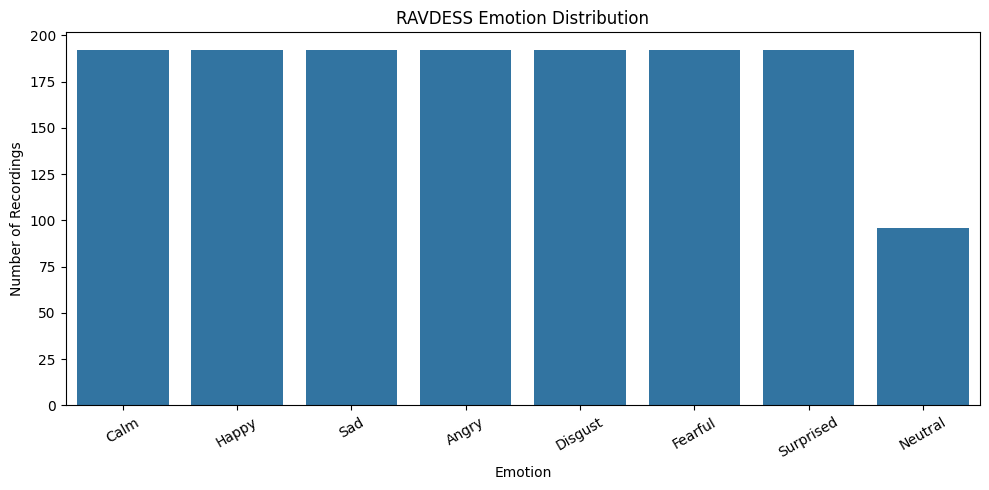

In [11]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="emotion_label",
    order=df["emotion_label"].value_counts().index
)

plt.title("RAVDESS Emotion Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Recordings")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [14]:
statement_mapping = {
    1: "Kids are talking by the door",
    2: "Dogs are sitting by the door"
}

df["statement_label"] = df["statement_id"].map(statement_mapping)

df.head()

,recording_id,file_path,actor_id,emotion_id,emotion_label,intensity,statement_id,repetition,modality,vocal_channel,statement_label
0,03-01-01-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,1,Neutral,Normal,1,1,Audio-only,Speech,Kids are talking by the door
1,03-01-01-01-01-02-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,1,Neutral,Normal,1,2,Audio-only,Speech,Kids are talking by the door
2,03-01-01-01-02-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,1,Neutral,Normal,2,1,Audio-only,Speech,Dogs are sitting by the door
3,03-01-01-01-02-02-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,1,Neutral,Normal,2,2,Audio-only,Speech,Dogs are sitting by the door
4,03-01-02-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,2,Calm,Normal,1,1,Audio-only,Speech,Kids are talking by the door


In [15]:
df.columns

Index(['recording_id', 'file_path', 'actor_id', 'emotion_id', 'emotion_label',
       'intensity', 'statement_id', 'repetition', 'modality', 'vocal_channel',
       'statement_label'],
      dtype='object')

# Extract audio properties

In [16]:
audio_properties = []

for file_path in audio_files:

    info = sf.info(file_path)

    audio_properties.append({
        "recording_id": file_path.stem,
        "duration": info.duration,
        "sample_rate": info.samplerate,
        "channels": info.channels,
        "frames": info.frames,
        "subtype": info.subtype
    })

audio_properties_df = pd.DataFrame(audio_properties)

df = df.merge(
    audio_properties_df,
    on="recording_id",
    how="left"
)

df.head()

,recording_id,file_path,actor_id,emotion_id,emotion_label,intensity,statement_id,repetition,modality,vocal_channel,statement_label,duration,sample_rate,channels,frames,subtype
0,03-01-01-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,1,Neutral,Normal,1,1,Audio-only,Speech,Kids are talking by the door,3.303292,48000,1,158558,PCM_16
1,03-01-01-01-01-02-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,1,Neutral,Normal,1,2,Audio-only,Speech,Kids are talking by the door,3.336667,48000,1,160160,PCM_16
2,03-01-01-01-02-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,1,Neutral,Normal,2,1,Audio-only,Speech,Dogs are sitting by the door,3.269917,48000,1,156956,PCM_16
3,03-01-01-01-02-02-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,1,Neutral,Normal,2,2,Audio-only,Speech,Dogs are sitting by the door,3.169833,48000,1,152152,PCM_16
4,03-01-02-01-01-01-01,Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH...,1,2,Calm,Normal,1,1,Audio-only,Speech,Kids are talking by the door,3.536854,48000,1,169769,PCM_16


In [17]:
df["duration"].describe()

count    1440.000000
mean        3.700665
std         0.336676
min         2.936271
25%         3.470146
50%         3.670333
75%         3.870542
max         5.271937
Name: duration, dtype: float64

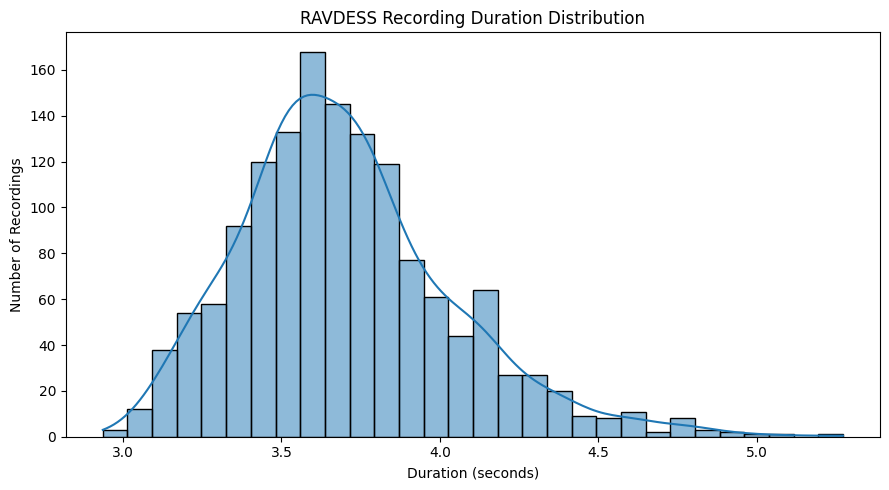

In [18]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="duration",
    bins=30,
    kde=True
)

plt.title("RAVDESS Recording Duration Distribution")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Recordings")

plt.tight_layout()
plt.show()

sample_rate
48000    1440
Name: count, dtype: int64


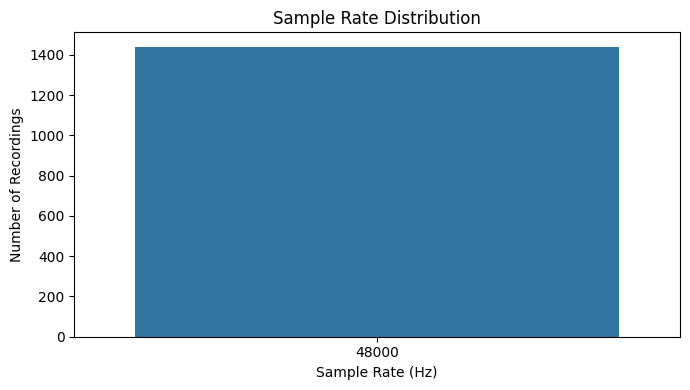

In [19]:
print(df["sample_rate"].value_counts())

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="sample_rate"
)

plt.title("Sample Rate Distribution")
plt.xlabel("Sample Rate (Hz)")
plt.ylabel("Number of Recordings")

plt.tight_layout()
plt.show()

channels
1    1435
2       5
Name: count, dtype: int64


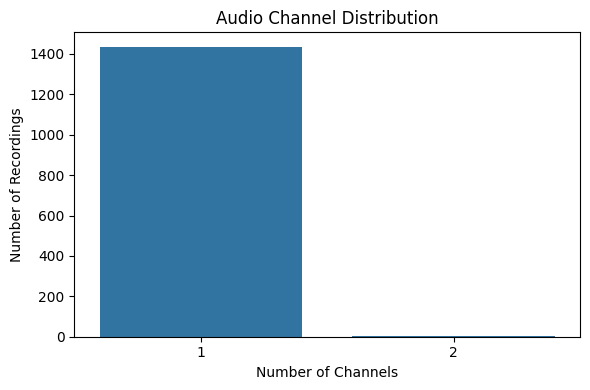

In [20]:
print(df["channels"].value_counts())

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="channels"
)

plt.title("Audio Channel Distribution")
plt.xlabel("Number of Channels")
plt.ylabel("Number of Recordings")

plt.tight_layout()
plt.show()

In [21]:
print("Audio encoding distribution:")
print(df["subtype"].value_counts())

Audio encoding distribution:
subtype
PCM_16    1440
Name: count, dtype: int64


In [22]:
print("========== RAVDESS DATASET SUMMARY ==========")

print("Total recordings:", len(df))
print("Total actors:", df["actor_id"].nunique())
print("Total emotions:", df["emotion_label"].nunique())

print("\nDuration:")
print("Minimum:", df["duration"].min())
print("Maximum:", df["duration"].max())
print("Mean:", df["duration"].mean())

print("\nSample rates:")
print(df["sample_rate"].value_counts())

print("\nAudio channels:")
print(df["channels"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

========== RAVDESS DATASET SUMMARY ==========
Total recordings: 1440
Total actors: 24
Total emotions: 8

Duration:
Minimum: 2.9362708333333334
Maximum: 5.2719375
Mean: 3.7006648148148145

Sample rates:
sample_rate
48000    1440
Name: count, dtype: int64

Audio channels:
channels
1    1435
2       5
Name: count, dtype: int64

Missing values:
recording_id       0
file_path          0
actor_id           0
emotion_id         0
emotion_label      0
intensity          0
statement_id       0
repetition         0
modality           0
vocal_channel      0
statement_label    0
duration           0
sample_rate        0
channels           0
frames             0
subtype            0
dtype: int64


# Investigate stereo recordings

In [23]:
stereo_files = df[df["channels"] > 1]

stereo_files[
    ["recording_id", "actor_id", "emotion_label",
     "sample_rate", "channels", "duration"]
]

,recording_id,actor_id,emotion_label,sample_rate,channels,duration
5,03-01-02-01-01-02-01,1,Calm,48000,2,3.603583
55,03-01-08-01-02-02-01,1,Surprised,48000,2,3.269917
247,03-01-02-01-02-02-05,5,Calm,48000,2,4.237563
1154,03-01-03-01-02-01-20,20,Happy,48000,2,3.470125
1177,03-01-06-01-01-02-20,20,Fearful,48000,2,4.371021


In [25]:
# Create processed data directory
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Save final metadata
metadata_path = PROCESSED_DIR / "metadata.csv"

df.to_csv(metadata_path, index=False)

print("Metadata saved successfully!")
print("Location:", metadata_path)
print("Shape:", df.shape)

Metadata saved successfully!
Location: Y:\Python\AI ML\Month 2\week 8-NLP\49 — SPEECH EMOTION RECOGNITION\data\processed\metadata.csv
Shape: (1440, 16)
